In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

In [2]:
train = pd.read_csv('train_combined.csv', parse_dates=['date'], low_memory=False)
print(train.shape)
train.dtypes

(3000888, 13)


id                       int64
date            datetime64[ns]
store_nbr                int64
family                  object
sales                  float64
onpromotion              int64
city                    object
state                   object
oil_price              float64
transactions           float64
type                    object
holiday                   bool
year_month              object
dtype: object

# 1. Eliminate store × family combination that were never sold out

If the sold/transaction record of (store_nbr, family) combination is 0 throughout the period, eliminate that rows. 
Only removing the rows that were never sold throughout the period.

In [3]:
total_sales_per_combo = train.groupby(['store_nbr', 'family'])['sales'].transform('sum')
never_sold_mask = total_sales_per_combo == 0

print("Total number of combination:", train.groupby(['store_nbr', 'family']).ngroups)
print("Combination that were never sold:", train.loc[never_sold_mask, ['store_nbr', 'family']].drop_duplicates().shape[0])
print("Number of eliminated rows:", never_sold_mask.sum())

before = len(train)
train = train.loc[~never_sold_mask].reset_index(drop=True)
print(f"no. rows: {before} -> {len(train)}")

Total number of combination: 1782
Combination that were never sold: 53
Number of eliminated rows: 89252
no. rows: 3000888 -> 2911636


# 2. Handling missing variable
## Oil Price
The missing oil price will be imputed by the average of forward-fill and backward-fill.
For 2013.01.01 data, where it is the beginning of data and has no former information, the price of the following day is imputed as we cannot 

In [4]:
oil_by_date = (train[['date', 'oil_price']]
               .drop_duplicates('date')
               .sort_values('date')
               .set_index('date')['oil_price'])

oil_ffill = oil_by_date.ffill()
oil_bfill = oil_by_date.bfill()
oil_filled = oil_by_date.fillna((oil_ffill + oil_bfill) / 2)
oil_filled = oil_filled.fillna(oil_ffill).fillna(oil_bfill)

print("number of missing values in oil_price:", train['oil_price'].isnull().sum())

number of missing values in oil_price: 900809


## Remove Christmas
It is not supposed to be there but make sure it is not in the dataset

In [5]:
dec25_mask = (train['date'].dt.month == 12) & (train['date'].dt.day == 25)
print("no. of 12/25:", dec25_mask.sum())

before = len(train)
train = train.loc[~dec25_mask].reset_index(drop=True)
print(f"no. rows: {before} -> {len(train)}")

no. of 12/25: 0
no. rows: 2911636 -> 2911636


# 3. Overlapping discriptor detection using Theil's U
U(x|y) shows how much does x can be determined by knowing y in 0 ~ 1. 
As the number close to 1, it represents y can almost perfectly explain x and both cannot be used as a descriptor

In [6]:
def conditional_entropy(x, y):
    """H(x|y): uncertainty of x given y"""
    y_counter = y.value_counts()
    xy_counter = pd.crosstab(x, y)
    total = len(x)
    h_xy = 0.0
    for yi in y_counter.index:
        p_y = y_counter[yi] / total
        col = xy_counter[yi]
        for n_xy in col:
            if n_xy > 0:
                p_xy = n_xy / total
                h_xy -= p_xy * np.log(p_xy / p_y)
    return h_xy

def theils_u(x, y):
    """U(x|y): how does uncertainty of x decreases if we know y (0 - 1, unsymmetrical)"""
    s = x.value_counts(normalize=True)
    h_x = -sum(p * np.log(p) for p in s if p > 0)
    if h_x == 0:
        return 1.0
    h_xy = conditional_entropy(x, y)
    return (h_x - h_xy) / h_x

cat_cols = ['store_nbr', 'city', 'state', 'family', 'type', 'holiday', 'year_month', 'date', 'onpromotion', 'oil_price', 'transactions']
train_cat = train[cat_cols].copy()
train_cat['type'] = train_cat['type'].fillna('NONE')

u_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for x, y in product(cat_cols, cat_cols):
    u_matrix.loc[x, y] = theils_u(train_cat[x].astype(str), train_cat[y].astype(str))

print(u_matrix.round(2))

print("\nU >= 0.95 pair:")
for x, y in product(cat_cols, cat_cols):
    if x != y and u_matrix.loc[x, y] >= 0.95:
        print(f"  U({x}|{y}) = {u_matrix.loc[x, y]:.2f}  ->  knowing {y} determins {x} almost 100%")

              store_nbr  city  state  family  type  holiday  year_month  date  \
store_nbr          1.00  0.62   0.54    0.01  0.00     0.00        0.00 -0.00   
city               1.00  1.00   0.87    0.00  0.00     0.00        0.00 -0.00   
state              1.00  1.00   1.00    0.00  0.00     0.00        0.00 -0.00   
family             0.01  0.00   0.00    1.00  0.00     0.00       -0.00  0.00   
type               0.00  0.00   0.00    0.00  1.00     0.69        0.35  0.97   
holiday            0.00  0.00   0.00    0.00  1.00     1.00        0.22  0.96   
year_month         0.00  0.00   0.00    0.00  0.04     0.02        1.00  1.00   
date               0.00  0.00   0.00   -0.00  0.06     0.04        0.54  1.00   
onpromotion        0.01  0.01   0.00    0.16  0.00     0.00        0.11  0.14   
oil_price          0.00  0.00   0.00    0.00  0.05     0.03        0.50  1.00   
transactions       0.22  0.10   0.08    0.00  0.01     0.00        0.13  0.50   

              onpromotion  

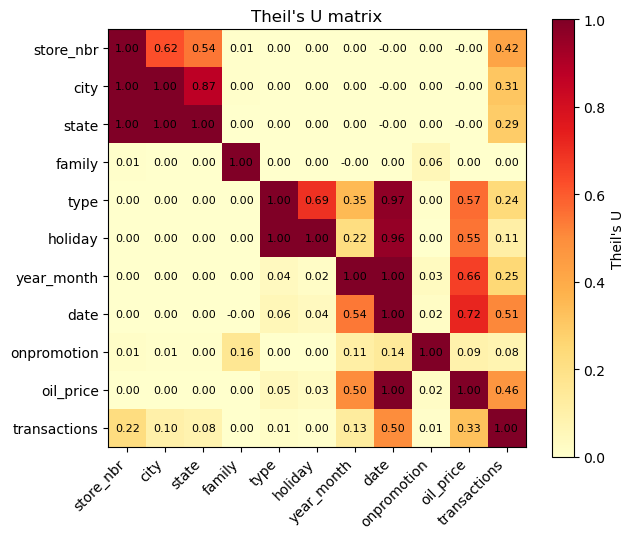

In [7]:
plt.figure(figsize=(6.5, 5.5))
im = plt.imshow(u_matrix.values.astype(float), cmap='YlOrRd', vmin=0, vmax=1)
plt.xticks(range(len(cat_cols)), cat_cols, rotation=45, ha='right')
plt.yticks(range(len(cat_cols)), cat_cols)
plt.colorbar(im, label="Theil's U")
for i in range(len(cat_cols)):
    for j in range(len(cat_cols)):
        plt.text(j, i, f"{u_matrix.values[i, j]:.2f}", ha='center', va='center', fontsize=8)
plt.title("Theil's U matrix")
plt.tight_layout()
plt.show()

# 4. Remove redundant discriptor
As it's shown in 3, `type` (describe which holiday is it), `state` (which state does the store located), `year_month` will be removed. `city` will not be removed as not all city has only 1 store.
`transactions` will be also removed as the target is `sales` and it can be leakage.

In [8]:
train_check = pd.read_csv('train_combined.csv', usecols=['store_nbr', 'city'], low_memory=False)
store_city = train_check[['store_nbr', 'city']].drop_duplicates()
city_counts = store_city.groupby('city')['store_nbr'].nunique().sort_values()

single = city_counts[city_counts == 1]
print(f"City with one store only: {len(single)} (out of {len(city_counts)} cities)")
print(single.index.tolist())

City with one store only: 14 (out of 22 cities)
['Babahoyo', 'Cayambe', 'Riobamba', 'Daule', 'El Carmen', 'Esmeraldas', 'Guaranda', 'Quevedo', 'Ibarra', 'Salinas', 'Libertad', 'Loja', 'Puyo', 'Playas']


In [9]:
train = train.drop(columns=['type', 'state', 'year_month', 'transactions'])
print(train.columns.tolist())

['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'city', 'oil_price', 'holiday']


# 5. Change data type for running algorithm
- `store_nbr`, `city`, `family` → **nominal (category)**
- `holiday` → **binary (bool)**
- `onpromotion`, `oil_price`, `transactions` → **numeric**

In [10]:
print("Before:")
print(train.dtypes)

train['store_nbr'] = train['store_nbr'].astype('category')
for col in ['city', 'family']:
    train[col] = train[col].astype('category')
train['holiday'] = train['holiday'].astype(bool)

train['onpromotion'] = train['onpromotion'].astype(int)
train['oil_price'] = train['oil_price'].astype(float)

print("After:")
print(train.dtypes)

Before:
id                      int64
date           datetime64[ns]
store_nbr               int64
family                 object
sales                 float64
onpromotion             int64
city                   object
oil_price             float64
holiday                  bool
dtype: object
After:
id                      int64
date           datetime64[ns]
store_nbr            category
family               category
sales                 float64
onpromotion             int32
city                 category
oil_price             float64
holiday                  bool
dtype: object


In [11]:
train.head()

,id,date,store_nbr,family,sales,onpromotion,city,oil_price,holiday
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,NaN,True
1,2,2013-01-01,1,BEAUTY,0.0,0,Quito,NaN,True
2,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,NaN,True
3,4,2013-01-01,1,BOOKS,0.0,0,Quito,NaN,True
4,5,2013-01-01,1,BREAD/BAKERY,0.0,0,Quito,NaN,True


In [12]:
train.to_csv('final_sales_dataset.csv', index=False)